In [18]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers, callbacks, datasets, models, optimizers
import matplotlib.pyplot as plt

In [3]:
# --- I. Préparation des données ---
(X_train, y_train) , (X_test , y_test) = keras.datasets.mnist.load_data()

In [4]:
# ---------(Normalisation 0 et 1) -----
X_train = X_train.astype("float32")/255
X_test  = X_test.astype("float32")/255

In [5]:
# --- Fonction générique pour créer les modèles (Q1, Q2, Q5, Q6) ---
def build_model(n_layers=0, n_neurons=128, use_l1=False, dropout_rate=0.0):
    model = models.Sequential([layers.Flatten(input_shape=(28, 28))])
    reg = regularizers.l1(0.01) if use_l1 else None
    
    for _ in range(n_layers):
        model.add(layers.Dense(n_neurons, activation='relu', kernel_regularizer=reg))
        if dropout_rate > 0: 
            model.add(layers.Dropout(dropout_rate)) # Q6: Dropout
            
    # Couche de sortie avec Softmax
    model.add(layers.Dense(10, activation='softmax', kernel_regularizer=reg))
    return model

In [28]:
#Q 1 et 2 et 3
model_3_layers = build_model(n_layers=3, n_neurons=128)

In [47]:
model_1_layer_eq = build_model(n_layers=1, n_neurons=169) # Modèle équivalent

In [48]:
print("MLP:",model_3_layers.count_params() , " /  P:" ,model_1_layer_eq.count_params())

MLP: 134794  /  P: 134365


In [37]:
# --- III, IV, V, VI. Modèle Final avec Validation, Adam, Dropout et Callbacks ---
model_final = build_model(n_layers=2, dropout_rate=0.1) # Q6: 10% de Dropout

In [31]:
# Q7: Utilisation de l'optimiseur Adam
model_final.compile(optimizer=optimizers.Adam(learning_rate=0.001), 
                    loss='sparse_categorical_crossentropy', 
                    metrics=['accuracy'])

In [38]:
# Configuration des Callbacks
mes_callbacks = [
    callbacks.TensorBoard(log_dir='./logs'), # Q10: TensorBoard
    callbacks.ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_loss'), # Q11: Enregistrement du meilleur modèle
    callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True) # Q12: Arrêt précoce
]

In [23]:
# Q4: Entraînement avec 30% de validation (validation_split=0.3)
history = model_final.fit(X_train, y_train, epochs=10, 
                          validation_split=0.3, callbacks=mes_callbacks)

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9107 - loss: 0.2998 - val_accuracy: 0.9536 - val_loss: 0.1571
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.9587 - loss: 0.1333 - val_accuracy: 0.9648 - val_loss: 0.1145
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.9680 - loss: 0.1007 - val_accuracy: 0.9687 - val_loss: 0.1061
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9745 - loss: 0.0799 - val_accuracy: 0.9713 - val_loss: 0.1037
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9788 - loss: 0.0659 - val_accuracy: 0.9713 - val_loss: 0.0971
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9811 - loss: 0.0568 - val_accuracy: 0.9714 - val_loss: 0.1020
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9839 - loss: 0.0481 - val_accuracy: 0.9700 - val_loss: 0.1139
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9860 - loss: 0.

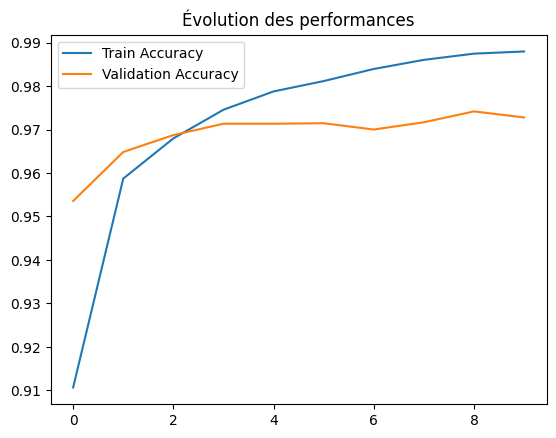

In [27]:
# --- Q9: Tracer les courbes d'évolution ---
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Évolution des performances")
plt.legend()
 